In [1]:
%pylab inline
import scanpy as sc
import pandas as pd
import seaborn as sns
import numpy as np
import sys
sys.path.append('./helpers/')
import matplotlib.pyplot as plt

sc.settings.n_jobs = 45
sc._settings.ScanpyConfig.n_jobs = 45  # 保留10核给系统
sc._settings.ScanpyConfig.max_memory = 300  # GB，保留20G给系统

from matplotlib import *
import matplotlib.pyplot as plt
rcParams['pdf.fonttype']=42 # in order to save fonttype in AI
rcParams['ps.fonttype']=42

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
ad_AIC = sc.read('./h5ad/ad_AIC_final.h5ad')
ad_AIC

AnnData object with n_obs × n_vars = 60534 × 20245
    obs: 'batch', 'Sex', 'TissueSample', 'BrainHemisphere', 'AutCtl', 'doublet_score', 'predicted_doublets', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'AnimalIDs', 'SampleIDs', 'Ages', 'cellClass', 'cellSubClass', 'cluster_IDs', 'cluster_labels'
    var: 'gene_ids', 'feature_types', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'batch_colors', 'cellClass_colors', 'cellSubClass_colors', 'cluster_IDs_colors', 'cluster_labels_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_harmonypca', 'X_pca', 'X_umap', 'X_umapharmony', 'X_umapraw'
    varm: 'PCs'
    layers: 'Counts'
    obsp: 'connectivities', 'distances'

/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


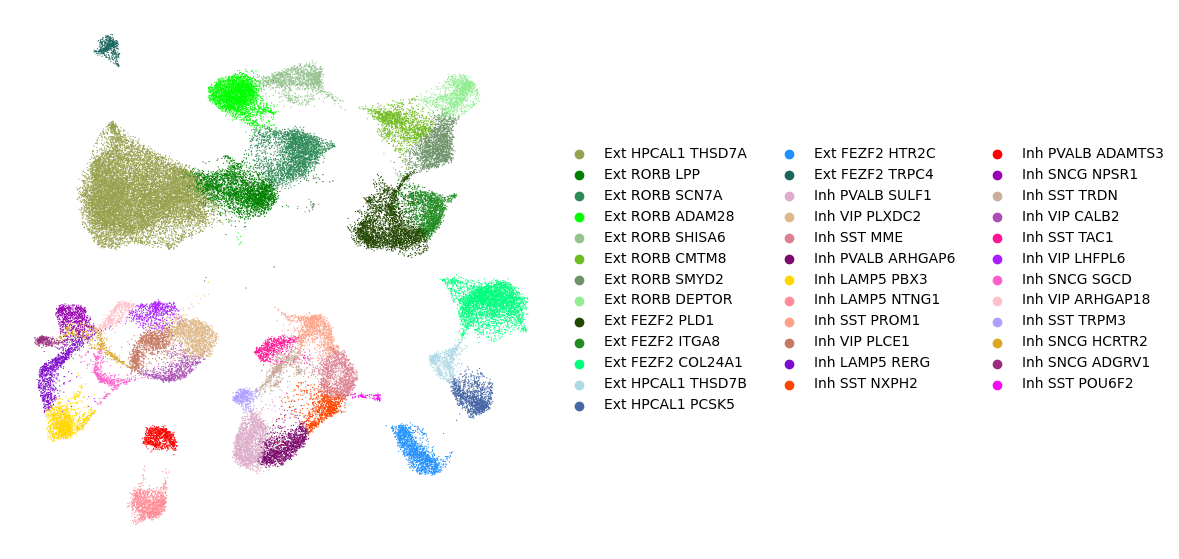

In [3]:
figsize(7,7)
sc.pl.umap(ad_AIC,color=['cluster_labels'],vmin=0,vmax=1.0, size=3, frameon='', title='')#, save='_cellTypes_allCells_AIC.pdf')

/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


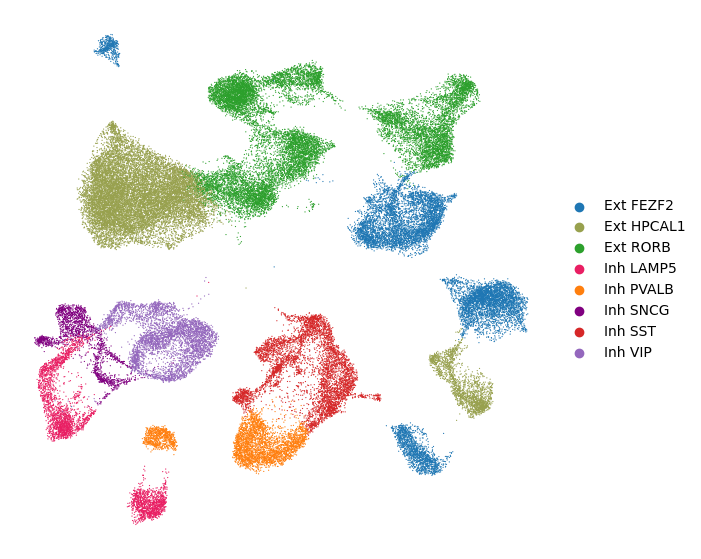

In [4]:
figsize(7,7)
sc.pl.umap(ad_AIC,color=['cellSubClass'],vmin=0,vmax=1.0, size=3, frameon='', title='')#, save='_subClassess_allCells_AIC.pdf')

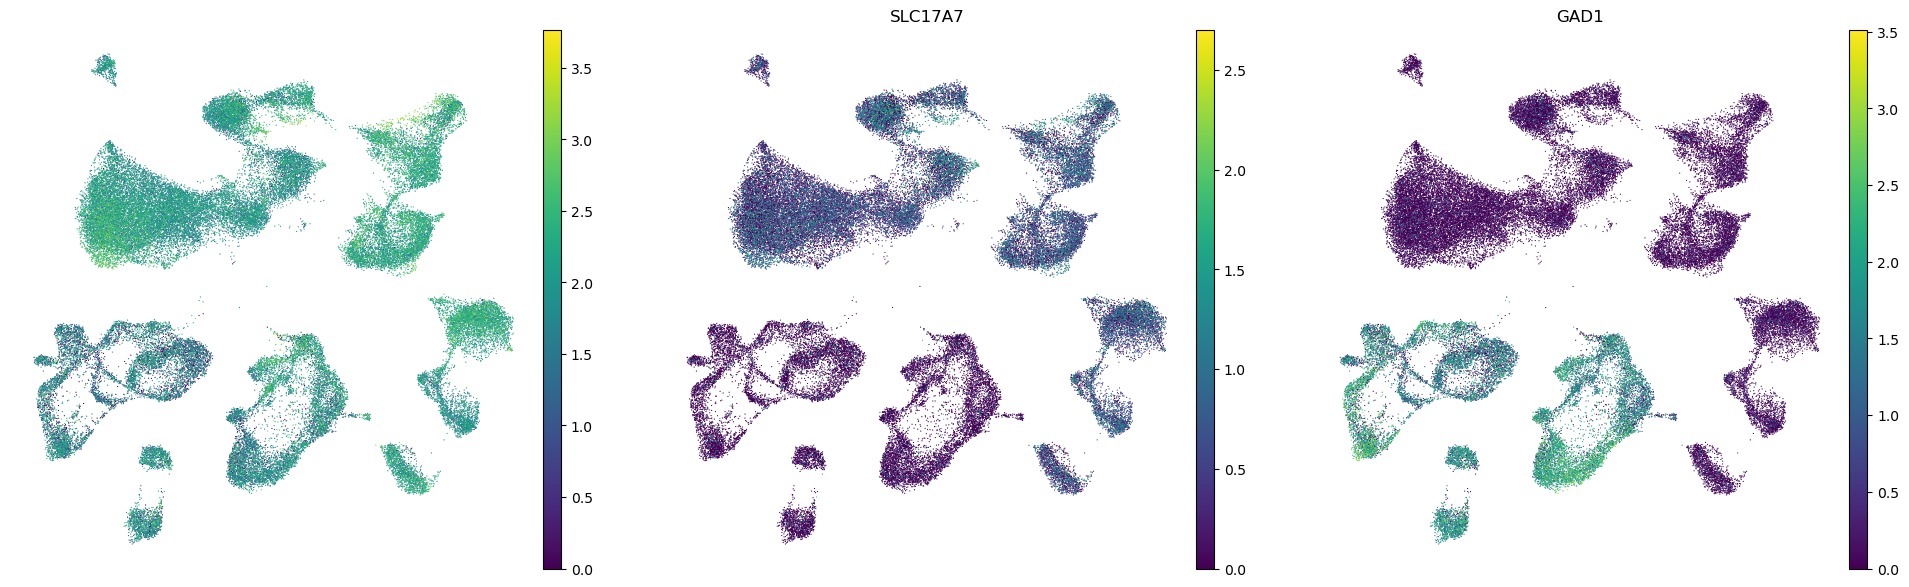

In [5]:
figsize(7,7)
sc.pl.umap(ad_AIC,color=['SNAP25','SLC17A7','GAD1'], size=3, frameon='', title='')#, save='_classMarkers_allCells_AIC.pdf')

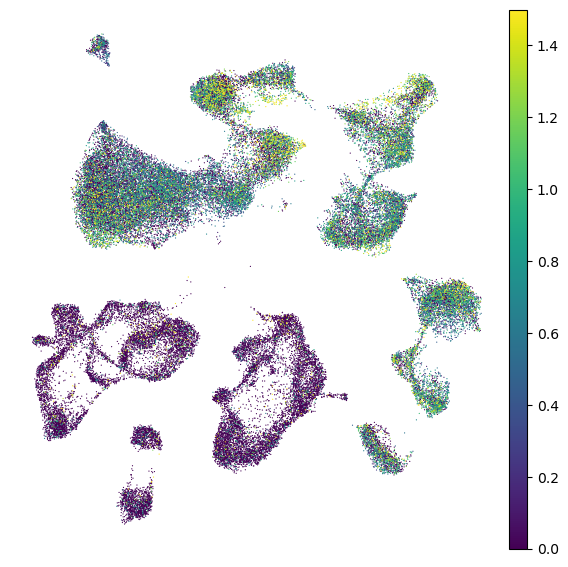

In [6]:
figsize(7,7)
sc.pl.umap(ad_AIC,color=['SLC17A7'], vmax=1.5, size=3, frameon='', title='')#, save='_SLC17A7_allCells_AIC.pdf')

/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


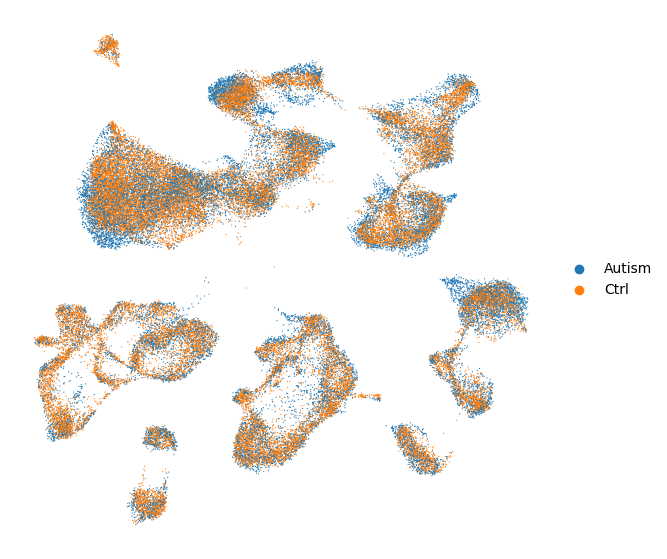

In [7]:
figsize(7,7)
sc.pl.umap(ad_AIC,color=['AutCtl'],vmin=0,vmax=1.0, size=3, frameon='', title='')#, save='_autismDistribution_allCells_AIC.pdf')

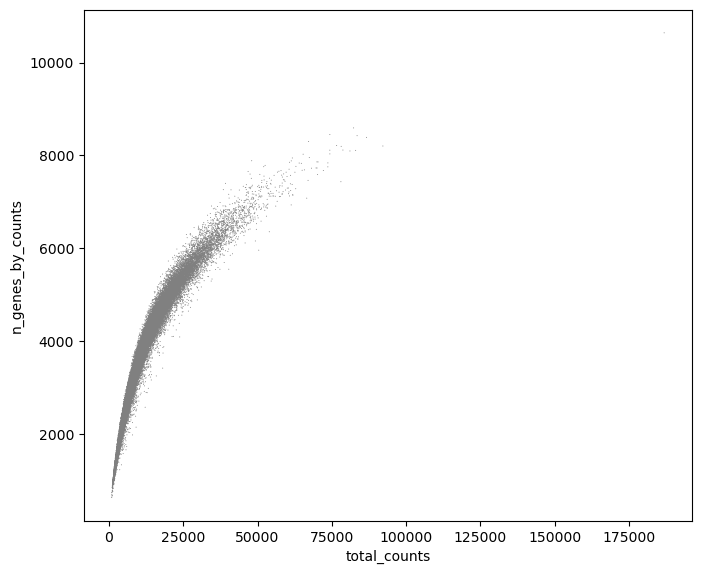

In [8]:
sc.pl.scatter(ad_AIC,  x='total_counts', y='n_genes_by_counts')#,save='_totalCounts_vs_NrGenes.pdf')

In [9]:
cluster_Names_2_newOrder = ad_AIC.obs['cluster_labels'].cat.categories

In [10]:
cell_label_reorder = cluster_Names_2_newOrder
# cell_label_reorder
cell_counts = pd.DataFrame(ad_AIC.obs['cluster_labels'].value_counts())
# cell_counts = cell_counts.reindex(cell_label_reorder)

cell_label = ad_AIC.obs['cluster_labels'].cat.categories
cell_color = list(ad_AIC.uns['cluster_labels_colors'])

In [11]:
heatmap_color = dict(zip(cell_label,cell_color))

In [12]:
cell_cat = cell_label_reorder 
cell_counts = pd.DataFrame(ad_AIC.obs['cluster_labels'].value_counts())
cell_counts = cell_counts.reindex(cell_cat)

# width of the bars
barWidth = 1
cell_type_all = list(cell_counts.index)    # becase the sequence distinction between ad.obs['cluster_Names_2'].cat.categories and ad.obs['cellType_labels_2'].cat.categories. we have to reorder the cellTpe labels in cell_type_all same as that in cellTypeID_2.

bar_color = dict(zip(cell_label,cell_color))
bar_color= pd.DataFrame.from_dict(heatmap_color, orient = 'index', columns = ['color'])
bar_color = bar_color.reindex(cell_label_reorder)

bars_original = np.array(cell_counts['cluster_labels'])
#bars1 = np.log10(bars_original)
bars1 = np.log10(bars_original)
#bars2 = mmmk_corr_rho.loc[key,:]
#bars3 = mmhu_HGNC_corr_rho.loc[cluster_key,gene_sets]

# The x position of bars
r1 = np.arange(len(bars1))
#r2 = [x + barWidth for x in r1]
#r3 = [x + barWidth + 0.05 for x in r1]
#p = humk_HGNC_corr_p_dif.loc[cluster_key,gene_sets] 

/tmp/ipykernel_2155/1466145023.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_type_all,rotation=90,size=8)


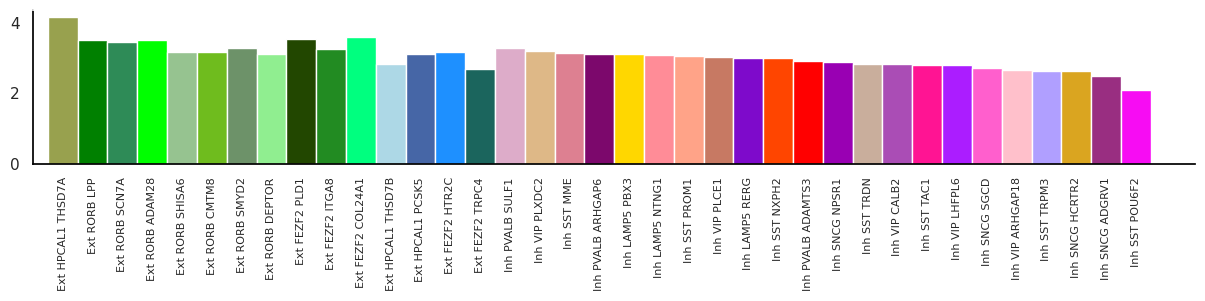

In [13]:
fig = plt.figure(figsize = (15,2))
plt.rcParams['font.size'] = '2'
    
gs = GridSpec(1, 1, figure=fig)
sns.set(font_scale=1)
    
    
ax = fig.add_subplot(gs[0, 0])
# Create bars
ax.bar(r1, bars1, width = barWidth, color = bar_color['color'])
# general layout
ax.set_yticks([0,2,4]) 
ax.set_xticklabels(cell_type_all,rotation=90,size=8)
ax.set_xticks(np.arange(len(cell_type_all)))
 
ax.set_xlim([-1,38])
# # Show graphic
# #plt.show()
ax.set_facecolor('white')
ax.spines['bottom'].set_color('#000000')
ax.spines['left'].set_color('#000000') 

# plt.savefig("figures/cellCounts4EachCellType_AIC.pdf", dpi = 600)

In [14]:
subCellTypeIDs = np.sort(ad_AIC.obs['cluster_IDs'].cat.codes.unique())
subCellTypeIDs
nSample = len(np.sort(ad_AIC.obs['TissueSample'].cat.codes.unique()))
nSample

8

In [15]:
n_cells = np.zeros([nSample,len(subCellTypeIDs)])
for sample in range(nSample):
    sampleData = ad_AIC[ad_AIC.obs['batch']=='batch-'+str(sample+1)]
    for subCellTypeID in subCellTypeIDs:
        n_cells[sample,subCellTypeID] = np.sum(sampleData.obs['cluster_IDs']==subCellTypeID)
 
    # n_cells[sample] = n_cells[sample]/np.sum(n_cells[sample,:])
nCell_percent = np.zeros([nSample,len(subCellTypeIDs)])
for sample in range(nSample):
    nCell_percent[sample] = n_cells[sample]/np.sum(n_cells[sample,:])
    

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


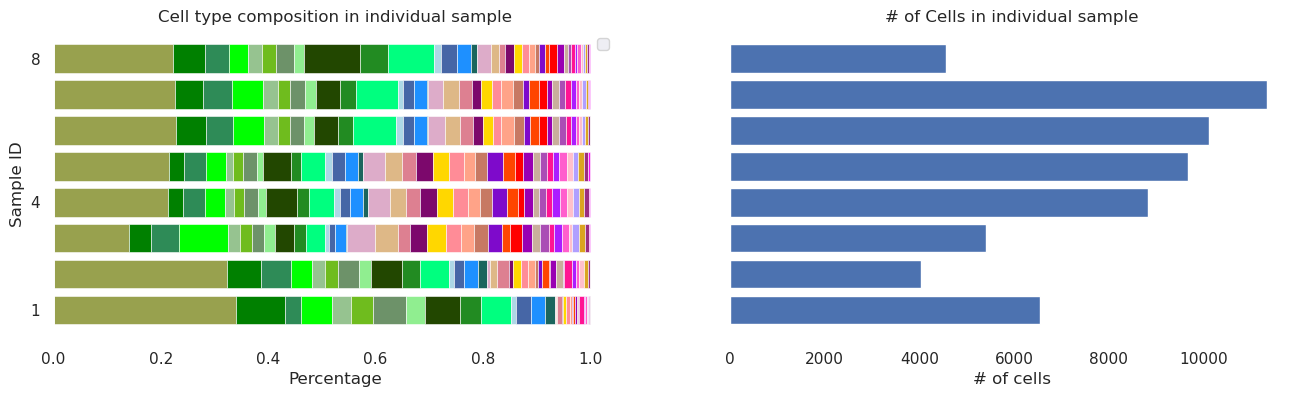

In [16]:
fig, axs = plt.subplots(1,2, figsize=(16,4), sharey=True)
width = 0.8
for i in range(len(subCellTypeIDs)):
    axs[0].barh(range(1,9,1), nCell_percent[:,i], width, left = np.sum(nCell_percent[:,:i],axis=1), color=bar_color['color'][ ad_AIC.obs['cluster_labels'].cat.categories[i]  ],linewidth=0.4)

axs[0].set_title("Cell type composition in individual sample")
axs[0].spines['right'].set_visible(True)
axs[0].spines['top'].set_visible(True)
axs[0].legend(loc="best")
axs[0].set_xlabel('Percentage')
axs[0].set_ylabel('Sample ID')
axs[0].set_facecolor('white')
axs[0].set_yticks([1, 4, 8])

# plot the number of cells in each sample
n_cells_sample = np.sum(n_cells,axis=1)
n_cells_sample
axs[1].barh(range(1,9,1),n_cells_sample, width, left=0)
axs[1].set_title("# of Cells in individual sample")
axs[1].spines['right'].set_visible(True)
axs[1].spines['top'].set_visible(True)
axs[1].set_xlabel('# of cells')
axs[1].set_facecolor('white')
axs[1].set_yticks([1, 4, 8])


# plt.savefig("figures/Fig_NrCellsStat_eachSample.pdf", dpi = 600)

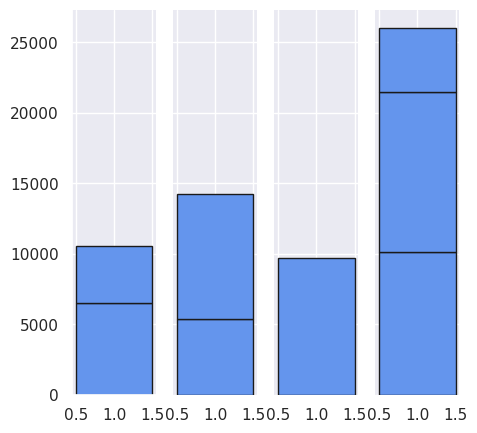

In [17]:
# Sample size in animals
n_cells_sample

animal1 = n_cells_sample[0:2]
animal2 = n_cells_sample[2:4]
animal3 = n_cells_sample[4:5]
animal4 = n_cells_sample[5:]

n_sample = np.array([len(animal1), len(animal2), len(animal3)] )

fig, ax = plt.subplots(1,4,figsize=(5,5), sharey=True)
barWidth = 1.0
for j in range(2):
    ax[0].bar(1,animal1[j],barWidth,bottom=np.sum(animal1[:j]),color='cornflowerblue',edgecolor='k' )
    ax[0].spines['right'].set_visible(False)
    ax[0].spines['top'].set_visible(False)
for j in range(2):
    ax[1].bar(1,animal2[j],barWidth,bottom=np.sum(animal2[:j]),color='cornflowerblue',edgecolor='k'  )
    ax[1].spines['right'].set_visible(False)
    ax[1].spines['top'].set_visible(False)
    ax[1].spines['left'].set_visible(False)
    ax[1].spines['bottom'].set_visible(False)
for j in range(1):
    ax[2].bar(1,animal3[j],barWidth,bottom=np.sum(animal3[:j]),color='cornflowerblue',edgecolor='k'  )
    ax[2].spines['right'].set_visible(False)
    ax[2].spines['top'].set_visible(False)
    ax[2].spines['left'].set_visible(False)
    ax[2].spines['bottom'].set_visible(False)
for j in range(3):
    ax[3].bar(1,animal4[j],barWidth,bottom=np.sum(animal4[:j]),color='cornflowerblue',edgecolor='k'  )
    ax[3].spines['right'].set_visible(False)
    ax[3].spines['top'].set_visible(False)
    ax[3].spines['left'].set_visible(False)
    ax[3].spines['bottom'].set_visible(False)

    
# plt.savefig("figures/NrCellsofSamplesFromEachAnimal_AIC.pdf", dpi = 600)

In [18]:
ad_Ext = sc.read('./h5ad/Ext.h5ad')
ad_Ext

AnnData object with n_obs × n_vars = 41681 × 20245
    obs: 'batch', 'Sex', 'TissueSample', 'BrainHemisphere', 'AutCtl', 'doublet_score', 'predicted_doublets', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'AnimalIDs', 'SampleIDs', 'Ages', 'cluster_IDs', 'cluster_labels', 'subClasses', 'classes'
    var: 'gene_ids', 'feature_types', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'batch_colors', 'classes_colors', 'cluster_IDs_colors', 'cluster_labels_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'subClasses_colors', 'umap'
    obsm: 'X_harmonypca', 'X_pca', 'X_umap', 'X_umapharmony', 'X_umapraw'
    varm: 'PCs'
    layers: 'Counts'
    obsp: 'connectivities', 'distances'

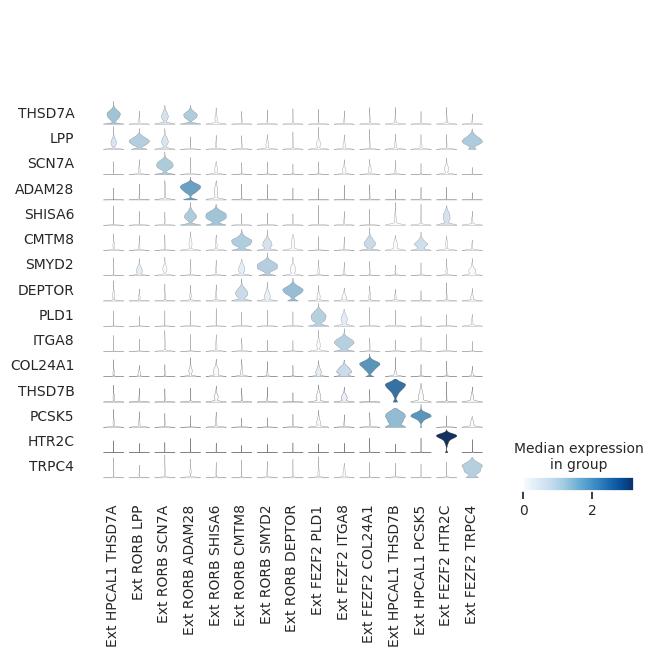

In [19]:
# Marker genes for each cell type
markerGenes = ['THSD7A',
               'LPP',     # CUX2
               'SCN7A',
               'ADAM28',
               'SHISA6',
               'CMTM8',
               'SMYD2',
               'DEPTOR',  # PTPRM
               'PLD1',
               'ITGA8',
               'COL24A1',  # NRP1, KAA1211, ADRA1A
               'THSD7B',   # RNF220, ADAMTSL1
               'PCSK5', 
               'HTR2C',    # NXPH2, SPON1, QRFPR
               'TRPC4',    # STXBP6, RIT2
              ]

sc.pl.stacked_violin(ad_Ext, markerGenes, groupby='cluster_labels',swap_axes = True,cmap='Blues')#, save='_Ext_markers.pdf')

In [20]:
np.max( ad_Ext[:,'POU6F2'].X )

ArrayView(3.5060167, dtype=float32)

In [21]:
ad_Inh = sc.read('./h5ad/Inh.h5ad')
ad_Inh

AnnData object with n_obs × n_vars = 18853 × 20245
    obs: 'batch', 'Sex', 'TissueSample', 'BrainHemisphere', 'AutCtl', 'doublet_score', 'predicted_doublets', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'AnimalIDs', 'SampleIDs', 'Ages', 'cluster_IDs', 'cluster_labels', 'subClasses', 'classes'
    var: 'gene_ids', 'feature_types', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'batch_colors', 'classes_colors', 'cluster_IDs_colors', 'cluster_labels_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'subClasses_colors', 'umap'
    obsm: 'X_harmonypca', 'X_pca', 'X_umap', 'X_umapharmony', 'X_umapraw'
    varm: 'PCs'
    layers: 'Counts'
    obsp: 'connectivities', 'distances'

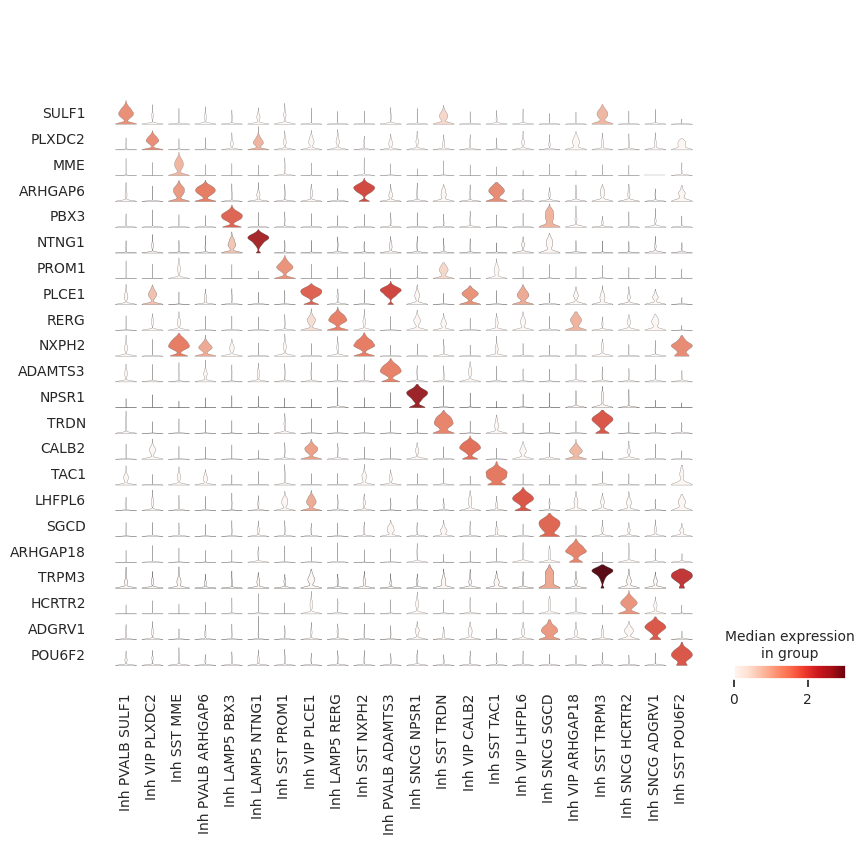

In [22]:
# Marker genes for each cell type
markerGenes = ['SULF1',  # 'POSTN','ETV6',''
               'PLXDC2',     # 
               'MME',  # SST
               'ARHGAP6',   # 'CCBE1'
               'PBX3',
               'NTNG1',   # FBN2  CPNE8
                'PROM1',  # CA10
               'PLCE1',  # 
               'RERG',
               'NXPH2',
               'ADAMTS3',  #  BPHA3  TRPS1
               'NPSR1',   # 
               'TRDN', 
               'CALB2',    # 
               'TAC1',    # 
               'LHFPL6',   # IQGAP2    15
               'SGCD',
               'ARHGAP18',  # 
               'TRPM3',   # 
               'HCRTR2', #  'CADPS2', 
               'ADGRV1',    # 
               'POU6F2',    #
              ]

sc.pl.stacked_violin(ad_Inh, markerGenes, groupby='cluster_labels', swap_axes = True, cmap='Reds',)

In [23]:
adata = sc.read('./data_tem/integratedNeurons_scRNA_vs_snRNA_final.h5ad')
adata

/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/anndata/_core/anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 98631 × 1500
    obs: 'batch', 'dataset', 'cellTypeID', 'cellTypeLabel', 'cell_subtypeID', 'cell_subtypeLabels', 'Sample', 'batch_ori', 'cluster_IDs', 'cluster_labels', 'n_genes_by_counts', 'total_counts', 'n_counts', 'louvain', 'louvain1_8', 'species'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'batch_ori_colors', 'dataset_colors', 'hvg', 'log1p', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'species_colors', 'umap'
    obsm: 'X_harmonypca', 'X_pca', 'X_umap', 'X_umapharmony', 'X_umapraw'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


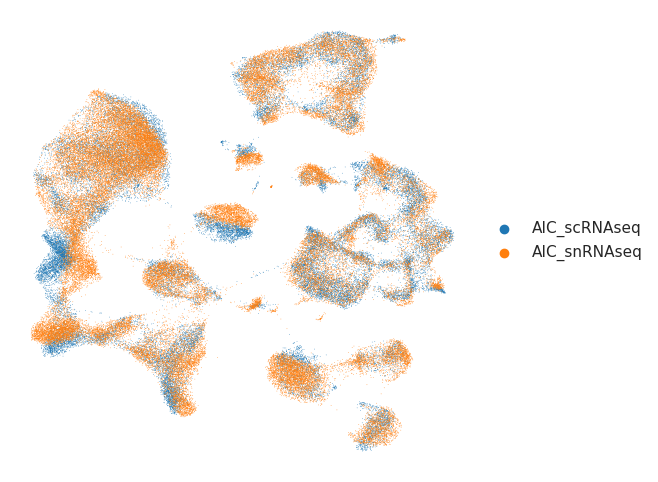

In [24]:
figsize(6,6)
sc.pl.umap(adata,color=['species'], size=1, frameon='', title='')#, save='_integratedCmp_AIC_scRNA_vs_SnRNA.pdf')

In [25]:
ad_AIC = sc.read('./h5ad/ad_AIC_final.h5ad')
ad_AIC

AnnData object with n_obs × n_vars = 60534 × 20245
    obs: 'batch', 'Sex', 'TissueSample', 'BrainHemisphere', 'AutCtl', 'doublet_score', 'predicted_doublets', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'AnimalIDs', 'SampleIDs', 'Ages', 'cellClass', 'cellSubClass', 'cluster_IDs', 'cluster_labels'
    var: 'gene_ids', 'feature_types', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'batch_colors', 'cellClass_colors', 'cellSubClass_colors', 'cluster_IDs_colors', 'cluster_labels_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_harmonypca', 'X_pca', 'X_umap', 'X_umapharmony', 'X_umapraw'
    varm: 'PCs'
    layers: 'Counts'
    obsp: 'connectivities', 'distances'

In [26]:
# load the Insular data...
ad_Ins = sc.read('/mnt/e/workDocs/JupyterNotebook/InsPatchSeq/10X/data_h5/Insular_sorted_clusters.h5ad')
ad_Ins = ad_Ins[ad_Ins.obs['cellTypeLabel'].isin(['Exc neuron','Inhib neuron'])]
ad_Ins

View of AnnData object with n_obs × n_vars = 38097 × 19944
    obs: 'batch', 'doublet_score', 'predicted_doublets', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'Sex', 'Sample', 'cellTypeID', 'cellTypeLabel', 'cell_subtypeID', 'cell_subtypeLabels', 'cellTypeID_2', 'cellType_labels_2', 'sampleLayers'
    var: 'gene_ids', 'feature_types', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'Sample_colors', 'Sex_colors', 'batch_colors', 'cellTypeID_2_colors', 'cellTypeID_colors', 'cellTypeLabel_colors', 'cellType_labels_2_colors', 'cell_subtypeID_colors', 'cell_subtypeLabels_colors', 'dendrogram_cellTypeLabel', 'dendrogram_cellType_labels_2', 'dendrogram_cell_subtypeLabels', 'hvg', 'neighbors', 'pca', 'rank_genes_groups', 'sampleLayers_colors', 'tsne', 'umap'
    obsm: 'X_harmonypca', 'X_pca', 'X_tsne', 'X_umap', 'X_umapharm

In [27]:
adata.obs['class'] = adata.obs_names.map(ad_AIC.obs['cellClass'])
adata.obs['class']

AAACCTGGTAGCTGCC-1-batch-1                  NaN
AAACCTGGTCAGAGGT-1-batch-1                  NaN
AAACCTGGTGGCGAAT-1-batch-1                  NaN
AAACGGGAGAAACCAT-1-batch-1                  NaN
AAACGGGGTAGCACGA-1-batch-1                  NaN
                                    ...        
TTTGTTGTCGTGAGAG-1-batch-7    Inhibitory Neuron
TTTGTTGTCTATCGTT-1-batch-6    Excitatory Neuron
TTTGTTGTCTCACTCG-1-batch-8    Inhibitory Neuron
TTTGTTGTCTGGAAGG-1-batch-4    Inhibitory Neuron
TTTGTTGTCTTACCAT-1-batch-6    Inhibitory Neuron
Name: class, Length: 98631, dtype: category
Categories (2, object): ['Excitatory Neuron', 'Inhibitory Neuron']

/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


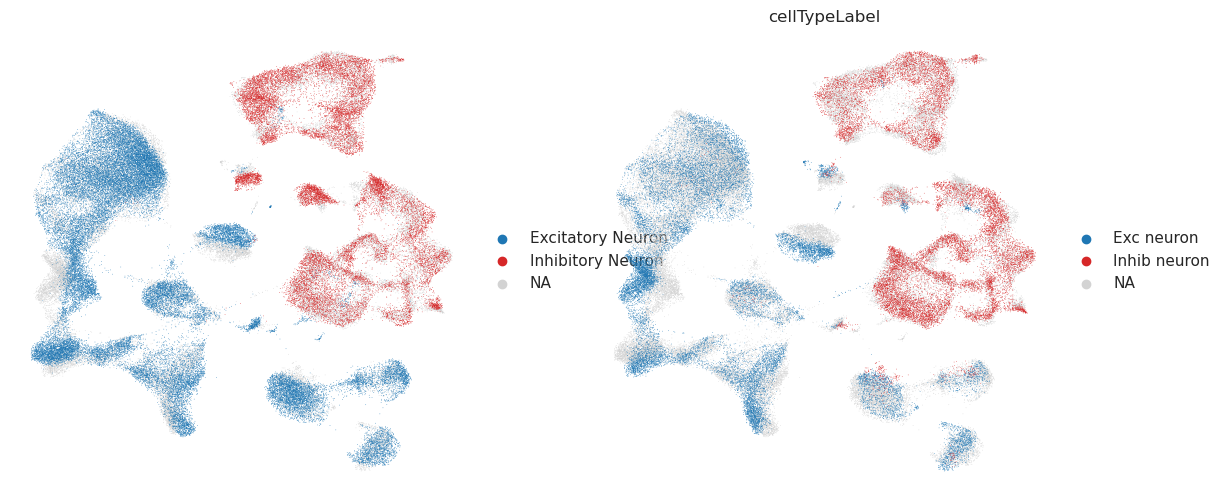

In [30]:
adata.uns['class_colors'] = ['#1f77b4', '#d62728']
adata.uns['cellTypeLabel_colors'] = ['#1f77b4', '#d62728']

figsize(6,6)
sc.pl.umap(adata,color=['class','cellTypeLabel'], size=1, frameon='', title='')#,save='_integrated_cellClass_snRNA_vs_scRNA.pdf')

/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


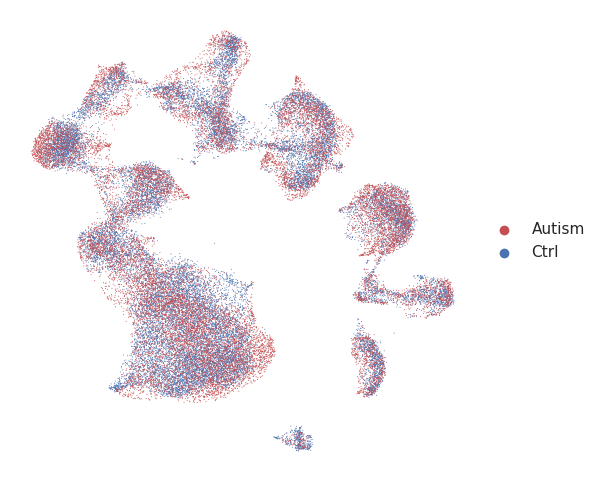

In [36]:
ad_Ext.uns['AutCtl_colors'] = ['#C44E52','#4C72B0'] 

figsize(6,6)
sc.pl.umap(ad_Ext,color=['AutCtl'], size=1, frameon='', title='',s=2)#, save='_integrated_Ext_Autism_vs_Control.pdf')

/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


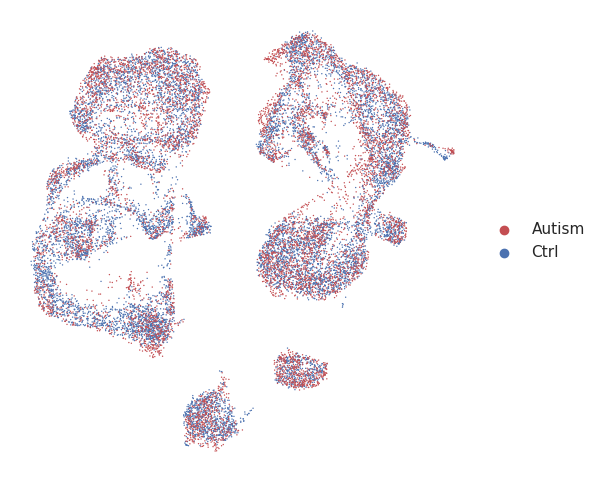

In [43]:
ad_Inh.uns['AutCtl_colors'] = ['#C44E52','#4C72B0'] 

figsize(6,6)
sc.pl.umap(ad_Inh,color=['AutCtl'], frameon='', title='',s=4)#, save='_integrated_Inh_Autism_vs_Control.pdf')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


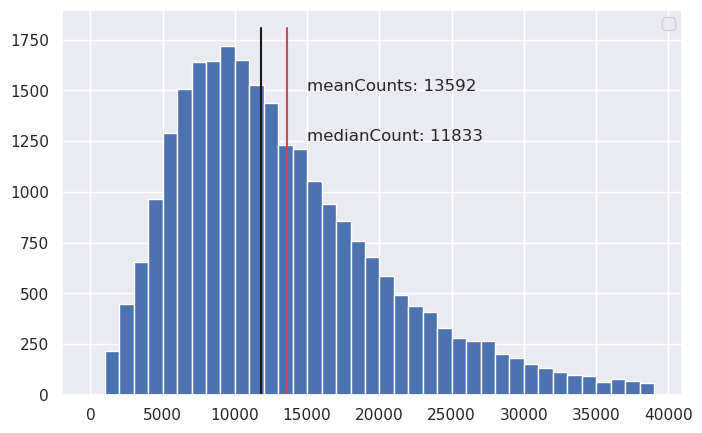

In [51]:
ad_aut = ad_AIC[ad_AIC.obs['AutCtl'].isin(['Autism'])]

# of cells relative to the UMI counts
figsize(8,5)
nCells_hist = hist(ad_aut.obs['total_counts'],bins=range(0,40000,1000))
meanCounts = np.mean(ad_aut.obs['total_counts'])
medianCount = np.median(ad_aut.obs['total_counts'])
# add figure properties.
ax = plt.gca()
ylim= ax.get_ylim()
ax.plot([meanCounts,meanCounts],ylim,c='r')
ax.plot([medianCount,medianCount],ylim,c='k')
ax.text(15000,1500, f'meanCounts: {meanCounts:.0f}')
ax.text(15000,1250, f'medianCount: {medianCount:.0f}')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.legend(loc='upper right')

ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

plt.savefig("figures/UMIcountsDistribution_AIC_autism.pdf", dpi = 600)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


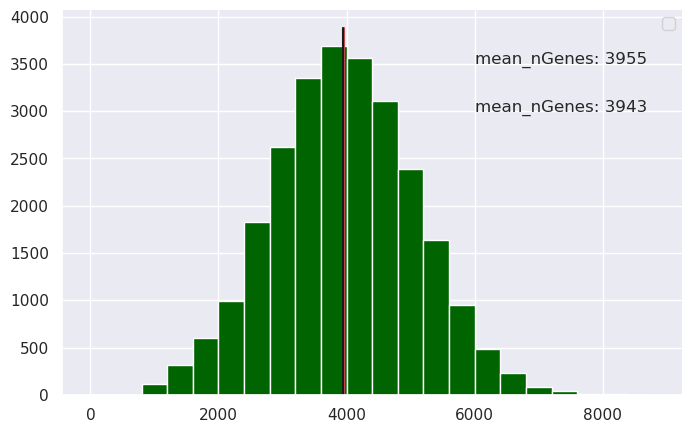

In [54]:
# of cells relative to the detected genes
figsize(8,5)
nCells_hist = hist(ad_aut.obs['n_genes'],bins=range(0,9000,400),color = 'darkgreen')
mean_nGenes = np.mean(ad_aut.obs['n_genes'])
median_nGenes = np.median(ad_aut.obs['n_genes'])
# add figure properties.
ax = plt.gca()
ylim= ax.get_ylim()
ax.plot([mean_nGenes,mean_nGenes],ylim,c='r')
ax.plot([median_nGenes,median_nGenes],ylim,c='k')
ax.text(6000, 3500, f'mean_nGenes: {mean_nGenes:.0f}')
ax.text(6000, 3000, f'mean_nGenes: {median_nGenes:.0f}')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.legend(loc='upper right')

plt.savefig("figures/detectedGenesDistribution_AIC_aut.pdf", dpi = 600)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


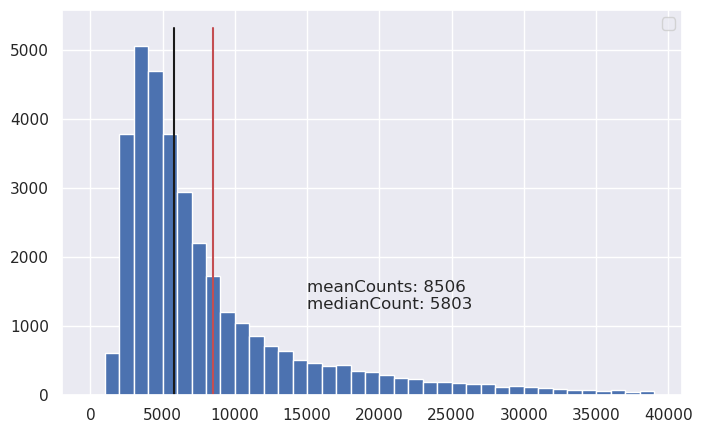

In [56]:
ad_ctrl = ad_AIC[ad_AIC.obs['AutCtl'].isin(['Ctrl'])]

# of cells relative to the UMI counts
figsize(8,5)
nCells_hist = hist(ad_ctrl.obs['total_counts'],bins=range(0,40000,1000))
meanCounts = np.mean(ad_ctrl.obs['total_counts'])
medianCount = np.median(ad_ctrl.obs['total_counts'])
# add figure properties.
ax = plt.gca()
ylim= ax.get_ylim()
ax.plot([meanCounts,meanCounts],ylim,c='r')
ax.plot([medianCount,medianCount],ylim,c='k')
ax.text(15000,1500, f'meanCounts: {meanCounts:.0f}')
ax.text(15000,1250, f'medianCount: {medianCount:.0f}')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.legend(loc='upper right')

ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

plt.savefig("figures/UMIcountsDistribution_AIC_Ctrl.pdf", dpi = 600)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


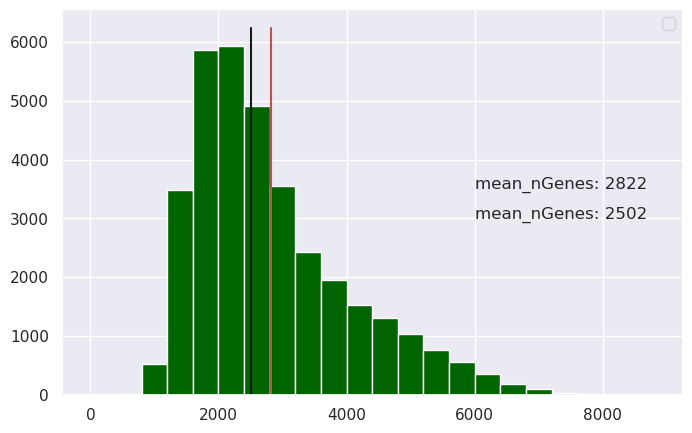

In [57]:
# of cells relative to the detected genes
figsize(8,5)
nCells_hist = hist(ad_ctrl.obs['n_genes'],bins=range(0,9000,400),color = 'darkgreen')
mean_nGenes = np.mean(ad_ctrl.obs['n_genes'])
median_nGenes = np.median(ad_ctrl.obs['n_genes'])
# add figure properties.
ax = plt.gca()
ylim= ax.get_ylim()
ax.plot([mean_nGenes,mean_nGenes],ylim,c='r')
ax.plot([median_nGenes,median_nGenes],ylim,c='k')
ax.text(6000, 3500, f'mean_nGenes: {mean_nGenes:.0f}')
ax.text(6000, 3000, f'mean_nGenes: {median_nGenes:.0f}')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.legend(loc='upper right')

plt.savefig("figures/detectedGenesDistribution_AIC_ctrl.pdf", dpi = 600)